> **Versi arsip ARIMAX-GARCH** (`arsip/arimax_garch/`, terpisah dari skripsi). SHAP hanya untuk
> keempat model jaringan saraf. Data model hybrid berjumlah 1.521 hari (dua hari pertama tidak
> memiliki `garch_vol`); data testing tetap 305 hari.

# 04 Interpretasi Model Terbaik dengan SHAP (Explainable AI)

Notebook ini menjelaskan **model terbaik** setiap emiten dengan SHAP (*SHapley Additive
exPlanations*), yaitu seberapa besar kontribusi setiap fitur terhadap prediksi harga.
Model tidak dilatih ulang: bobot dan scaler dimuat dari `outputs/model/` (hasil notebook
02). Keluarannya sengaja dibuat ringkas: persentase kontribusi setiap fitur (dicetak) dan
satu grafik batang untuk setiap model terbaik.

## Mekanisme SHAP

**1. Nilai Shapley.** SHAP berasal dari teori permainan kooperatif. Kontribusi fitur $i$
adalah rata-rata tambahan prediksi ketika fitur $i$ ikut dimasukkan, dihitung atas semua
kemungkinan kelompok (koalisi) fitur lain $S$:

$$\phi_i = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,\Big[f(S \cup \{i\}) - f(S)\Big]$$

dengan $F$ himpunan seluruh fitur dan $f(S)$ prediksi model bila hanya fitur dalam $S$
yang diketahui.

**2. Sifat aditif.** Prediksi model sama dengan nilai dasar ditambah jumlah kontribusi
seluruh fitur:

$$f(x) = \phi_0 + \sum_{i=1}^{M} \phi_i, \qquad \phi_0 = E\big[f(X)\big]$$

$\phi_0$ adalah rata-rata prediksi pada data acuan (*background*). $\phi_i$ positif
berarti fitur menaikkan prediksi, negatif berarti menurunkan.

**3. GradientExplainer (*expected gradients*).** Menghitung semua koalisi tidak mungkin
untuk jaringan saraf, sehingga $\phi$ diaproksimasi dengan gradien model sepanjang garis
dari data acuan $x'$ ke input $x$:

$$\phi_i \approx \mathbb{E}_{x' \sim D,\ \alpha \sim U(0,1)}\left[(x_i - x'_i)\,\frac{\partial f\big(x' + \alpha\,(x - x')\big)}{\partial x_i}\right]$$

$D$ adalah 100 window acak dari data training final (seed 42), dan ekspektasi diestimasi
dengan 200 sampel (seed 42), sehingga hasilnya dapat diulang.

**4. Agregasi ke tingkat fitur.** Masukan model adalah window 60 hari × jumlah fitur,
sehingga setiap prediksi memiliki nilai SHAP untuk setiap pasangan (hari $t$, fitur $f$).
Kontribusi fitur dan persentasenya:

$$I_f = \frac{1}{n}\sum_{k=1}^{n}\sum_{t=1}^{60}\left|\phi_{k,t,f}\right|, \qquad P_f = \frac{I_f}{\sum_{g} I_g} \times 100\%$$

dengan $n = 305$ window data testing. $P_f$ adalah persentase kontribusi fitur $f$.

Catatan: SHAP pada jaringan rekuren adalah aproksimasi. Kontribusi fitur bukan hubungan
sebab-akibat, dan fitur yang saling berkorelasi berbagi kontribusi.

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import shap

MODEL_NN = ["LSTM", "GRU", "GARCH-LSTM", "GARCH-GRU"]   # SHAP hanya untuk model jaringan saraf
EMITEN_LIST = ["ANTM", "INCO"]
SEED = 42
WINDOW = 60
N_BACKGROUND = 100
N_SAMPEL = 200
BERKAS_XLSX = "outputs/04_interpretasi_shap.xlsx"
tabel = {}   # seluruh tabel yang disimpan ke xlsx


class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, dropout):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.dropout(out)
        return self.fc(out)


class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, dropout):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        out = out[:, -1, :]
        out = self.dropout(out)
        return self.fc(out)

## 1. Model terbaik

Model terbaik setiap emiten adalah model dengan MAPE terkecil pada data testing di antara
keempat model jaringan saraf (sheet `metrik_{E}` di `outputs/03_perbandingan.xlsx`). RMSE dan
MAE diperiksa harus menunjuk model yang sama. ARIMAX-GARCH tidak diikutkan karena SHAP
GradientExplainer hanya berlaku untuk jaringan saraf.

In [2]:
model_terbaik = {}
baris = []
for e in EMITEN_LIST:
    metrik = pd.read_excel("outputs/03_perbandingan.xlsx", sheet_name="metrik_" + e)
    metrik = metrik[metrik["model"].isin(MODEL_NN)].reset_index(drop=True)   # tanpa ARIMAX-GARCH
    terbaik = metrik.loc[metrik["mape"].idxmin(), "model"]   # MAPE terkecil
    assert terbaik == metrik.loc[metrik["rmse"].idxmin(), "model"] == metrik.loc[metrik["mae"].idxmin(), "model"]
    model_terbaik[e] = terbaik
    baris.append([e, terbaik] + metrik[metrik["model"] == terbaik][["rmse", "mae", "mape"]].values[0].tolist())
    print(e, ": model terbaik =", terbaik)
tabel["model_terbaik"] = pd.DataFrame(baris, columns=["emiten", "model", "rmse", "mae", "mape"])

ANTM : model terbaik = LSTM
INCO : model terbaik = LSTM


## 2. Kontribusi fitur (SHAP)

Untuk setiap model terbaik: model dan scaler dimuat, lalu diperiksa bahwa prediksinya
sama dengan sheet `prediksi` notebook 02. Nilai SHAP dihitung untuk 305 window data
testing, lalu diringkas menjadi persentase kontribusi setiap fitur.

ANTM - LSTM : persentase kontribusi fitur
    antm = 77,11 %
    emas = 21,36 %
    nikel = 1,53 %


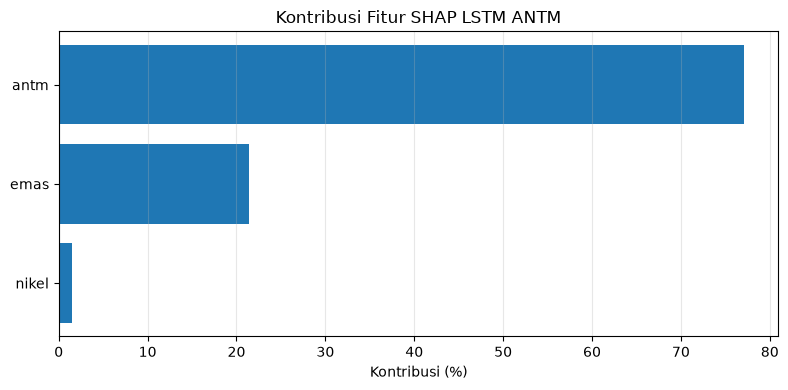

INCO - LSTM : persentase kontribusi fitur
    inco = 94,36 %
    nikel = 5,64 %


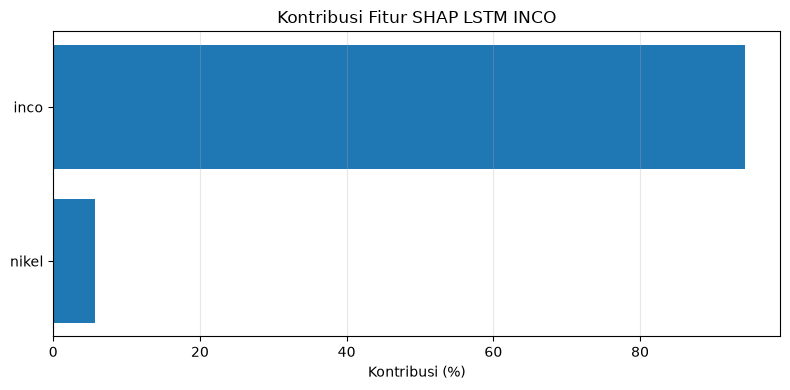

In [3]:
for e in EMITEN_LIST:
    m = model_terbaik[e]
    nama = m + "_" + e
    hasil_02 = pd.ExcelFile("outputs/02_" + nama + ".xlsx")
    bp = hasil_02.parse("best_params").iloc[0]
    n_trainval = int(hasil_02.parse("pembagian_data")["jumlah"].iloc[1])
    n_train_final = int(hasil_02.parse("pembagian_fold")["jumlah_training"].iloc[-1])

    # dataset sama dengan notebook 02
    data = pd.read_csv("data/data_" + e.lower() + ".csv")
    data["Tanggal"] = pd.to_datetime(data["Tanggal"])
    if m.startswith("GARCH"):
        data = data.iloc[2:].reset_index(drop=True)   # hybrid: dua hari pertama tidak memiliki garch_vol
        vol = pd.read_excel("outputs/01_arimax_garch_" + e + ".xlsx", sheet_name="conditional_volatility")
        vol = vol[["Tanggal", "sigma"]].rename(columns={"sigma": "garch_vol"})
        vol["Tanggal"] = pd.to_datetime(vol["Tanggal"])
        data = data.merge(vol, on="Tanggal", how="left")
    assert data.isna().sum().sum() == 0
    fitur = list(data.columns[1:])

    # model dan scaler tersimpan
    scaler_fitur = pickle.load(open("outputs/model/scaler_fitur_" + nama + ".pkl", "rb"))
    scaler_target = pickle.load(open("outputs/model/scaler_target_" + nama + ".pkl", "rb"))
    kelas = LSTMModel if m.endswith("LSTM") else GRUModel
    model = kelas(len(fitur), int(bp["hidden_size"]), float(bp["dropout"]))
    model.load_state_dict(torch.load("outputs/model/model_" + nama + ".pt", map_location="cpu"))
    model.eval()

    nilai = scaler_fitur.transform(data[fitur].values)
    X_train = np.array([nilai[i - WINDOW:i] for i in range(WINDOW, n_train_final)])
    X_test = np.array([nilai[i - WINDOW:i] for i in range(n_trainval, len(data))])
    assert len(X_test) == 305

    # pemeriksaan: model yang dimuat menghasilkan prediksi yang sama dengan notebook 02
    with torch.no_grad():
        prediksi = scaler_target.inverse_transform(model(torch.tensor(X_test, dtype=torch.float32)).numpy()).ravel()
    assert np.allclose(prediksi, hasil_02.parse("prediksi")["prediksi"].values, atol=0.01)

    # SHAP (GradientExplainer) dengan 100 window acak data training final sebagai acuan
    rng = np.random.default_rng(SEED)
    background = X_train[np.sort(rng.choice(len(X_train), N_BACKGROUND, replace=False))]
    explainer = shap.GradientExplainer(model, torch.tensor(background, dtype=torch.float32))
    nilai_shap = explainer.shap_values(torch.tensor(X_test, dtype=torch.float32), nsamples=N_SAMPEL, rseed=SEED)
    nilai_shap = np.array(nilai_shap).reshape(len(X_test), WINDOW, len(fitur))

    # I_f = rata-rata (atas window testing) dari jumlah |SHAP| di 60 hari; P_f = persentase
    kontribusi = np.abs(nilai_shap).sum(axis=1).mean(axis=0)
    persentase = kontribusi / kontribusi.sum() * 100
    tabel["shap_" + e] = pd.DataFrame({"fitur": fitur, "persentase": persentase})

    print(e, "-", m, ": persentase kontribusi fitur")
    for f, p in zip(fitur, persentase):
        print("   ", f, "=", f"{p:.2f}".replace(".", ","), "%")

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(fitur, persentase, color="tab:blue")
    ax.invert_yaxis()
    ax.set_title("Kontribusi Fitur SHAP " + m + " " + e)
    ax.set_xlabel("Kontribusi (%)")
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.savefig("outputs/gambar_shap_" + nama + ".png", dpi=300)
    plt.show()

## 3. Simpan tabel

Tabel model terbaik dan persentase kontribusi fitur disimpan ke
`outputs/04_interpretasi_shap.xlsx`.

In [4]:
with pd.ExcelWriter(BERKAS_XLSX) as writer:
    for nama_sheet in tabel:
        tabel[nama_sheet].to_excel(writer, sheet_name=nama_sheet, index=False)